In [1]:
import pandas as pd

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)


In [2]:
display(df.head())
display(df.describe())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,...,month,day_of_week,day_of_month,week_of_year,day_of_year,is_weekend,is_holiday,tavg,tmin,tmax
date,,,,,,,,,,,,,,,,,,,,,
2016-04-01,73,8154.0,1700,90,4.0,0.0,1459468800,1704.0,0.044444,1734.893617,...,4,4,1,13,92,False,False,8.3,5.0,13.1
2016-04-02,64,8526.0,1700,90,70.0,0.0,1459555200,1770.0,0.777778,1814.042553,...,4,5,2,13,93,True,False,9.9,1.3,16.4
2016-04-03,68,8088.0,1700,90,0.0,0.0,1459641600,1700.0,0.000000,1720.851064,...,4,6,3,13,94,True,False,13.1,6.1,19.1
2016-04-04,71,7044.0,1700,90,0.0,0.0,1459728000,1700.0,0.000000,1498.723404,...,4,0,4,14,95,False,False,15.2,9.5,20.6
2016-04-05,63,7236.0,1700,90,0.0,0.0,1459814400,1700.0,0.000000,1539.574468,...,4,1,5,14,96,False,False,16.0,8.4,22.7


,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,...,call_stress,year,month,day_of_week,day_of_month,week_of_year,day_of_year,tavg,tmin,tmax
count,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000,1.152000e+03,1152.000000,1152.000000,1152.000000,...,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1833.333333,90.0,30.182292,16.335938,1.509192e+09,1863.515625,0.335359,1685.006649,...,4.238179,2017.333333,6.424479,3.002604,15.674479,26.023438,180.072049,11.268229,7.051997,15.467882
std,14.293942,1290.063571,97.759435,0.0,71.753595,53.394089,2.874511e+07,124.273086,0.797262,274.481611,...,0.541139,0.977594,3.394101,2.002386,8.778030,14.770423,103.880984,7.711124,6.679351,9.095201
min,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000,1.459469e+09,1700.000000,0.000000,866.808511,...,2.263333,2016.000000,1.000000,0.000000,1.000000,1.000000,1.000000,-8.800000,-12.800000,-5.800000
25%,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000,1.484330e+09,1800.000000,0.000000,1484.680851,...,3.860882,2017.000000,4.000000,1.000000,8.000000,14.000000,95.000000,5.200000,1.900000,7.900000
50%,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000,1.509192e+09,1874.500000,0.000000,1687.659574,...,4.323158,2017.000000,6.000000,3.000000,16.000000,25.000000,174.000000,10.600000,6.700000,14.950000
75%,78.000000,8827.500000,1900.000000,90.0,0.000000,0.000000,1.534054e+09,1905.250000,0.000000,1878.191489,...,4.765372,2018.000000,9.000000,5.000000,23.000000,39.000000,270.000000,17.800000,12.400000,23.000000
max,119.000000,11850.000000,2000.000000,90.0,461.000000,465.000000,1.558915e+09,2455.000000,5.122222,2521.276596,...,4.896288,2019.000000,12.000000,6.000000,31.000000,52.000000,366.000000,28.900000,23.900000,38.000000


In [8]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error
import matplotlib.pyplot as plt

def plot_regression_predictions(y_true: pd.DataFrame, y_pred: pd.DataFrame, y_train: pd.DataFrame = None, annotation : str = "", additional_column_df : pd.DataFrame = None) -> None:
    
    # Metrics
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)

    mape = mean_absolute_percentage_error(y_true, y_pred)

    # Plot 
    plt.figure(figsize=(10, 6))
    plt.title(f'Prediction results' + (f" ({annotation})" if annotation else ""))

    if y_train is not None:
        plt.plot(y_train.index, y_train, label='Train', color='blue')

    plt.plot(y_true.index, y_true, label='Test', color='green')
    plt.plot(y_true.index, y_pred, label='Predictions', color='red')

    if additional_column_df is not None:

        max_value = max([
        y_true.select_dtypes(include=[float, int]).max().max(),
        y_pred.select_dtypes(include=[float, int]).max().max(),
        additional_column_df.select_dtypes(include=[float, int]).max().max(),
        ])

        for column in additional_column_df.columns:
            if additional_column_df[column].dtype == bool:
                plt.plot(additional_column_df.index, additional_column_df[column].astype(int) * max_value, label =  "+ " +column + " (bool)", linestyle="dotted")
            else:
                plt.plot(additional_column_df.index, additional_column_df[column], label = "+ " + column)

    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)

    textstr = '\n'.join((
        r'$R^2=%.2f$' % (r2, ),
        r'$MAE=%.2f$' % (mae, ),
        r'$RMSE=%.2f$' % (rmse, )))

    print(textstr)

    plt.text(0.8, 0.2, textstr, transform=plt.gca().transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

    plt.legend()
    plt.grid()
    plt.show()


NameError: name 'test' is not defined

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.9641 - mae: 0.8066 - val_loss: 0.7930 - val_mae: 0.7081
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.8276 - mae: 0.7523 - val_loss: 0.5940 - val_mae: 0.6210
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7399 - mae: 0.7067 - val_loss: 0.5542 - val_mae: 0.6092
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6883 - mae: 0.6714 - val_loss: 0.5769 - val_mae: 0.6260
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6947 - mae: 0.6739 - val_loss: 0.5506 - val_mae: 0.6106
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7315 - mae: 0.7053 - val_loss: 0.5797 - val_mae: 0.6231
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6422 - mae: 0.6544 - val_loss: 0.6950 - val_mae: 0.6795
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6379 - mae: 0.6654 - val_loss: 0.7650 - val_mae: 0.7103
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6134 - mae:

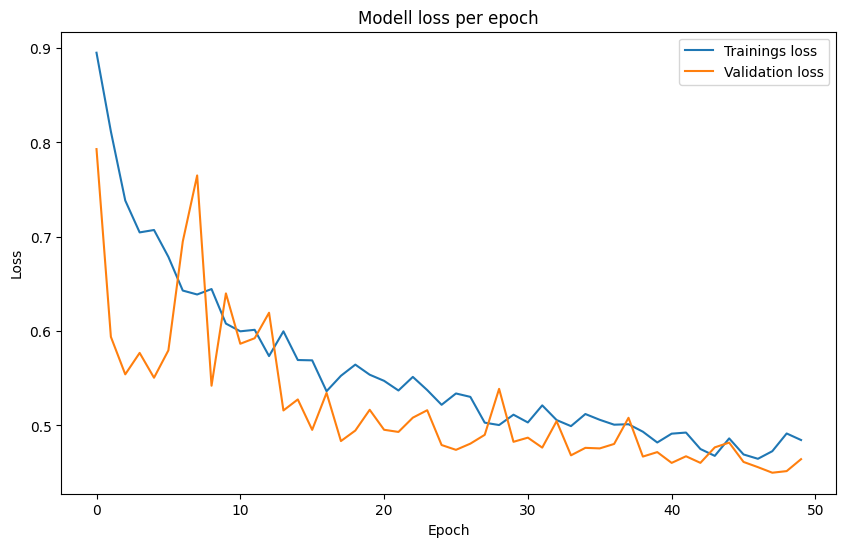

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
R2-Score: 0.3475396592532839
              True    Predicted
date                           
2018-10-15  7194.0  8320.614258
2018-10-16  9300.0  8424.561523
2018-10-17  9834.0  8334.692383
2018-10-18  8874.0  8129.238770
2018-10-19  6852.0  7916.051270
...            ...          ...
2019-05-23  8544.0  9327.068359
2019-05-24  8814.0  9293.523438
2019-05-25  9846.0  9382.499023
2019-05-26  9882.0  9631.706055
2019-05-27  8790.0  9689.122070

[225 rows x 2 columns]
$R^2=0.35$
$MAE=882.38$
$RMSE=1052.51$


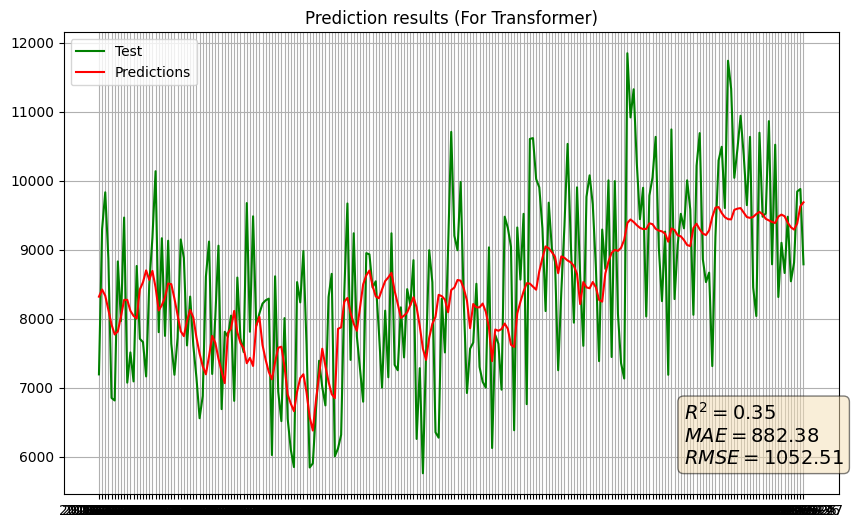

In [11]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Daten mit Ziel- und exogenen Features
target_column_name = "calls"
exogenous_features = ["day_of_week", "day_of_month", "day_of_year", "year"]

data = df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Skalierer für Features und Zielspalte
scaler_x = StandardScaler()
scaler_y = StandardScaler()

# Exogene Features und Zielspalte trennen und separat skalieren
scaled_x = scaler_x.fit_transform(data[exogenous_features])
scaled_y = scaler_y.fit_transform(data[[target_column_name]])

# Sequenzen erstellen
def create_sequences(data_x, data_y, seq_length):
    xs, ys = [], []
    for i in range(len(data_x) - seq_length):
        x = data_x[i:i + seq_length]
        y = data_y[i + seq_length]  # Zielwert ist um `seq_length` verschoben
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_x, scaled_y, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super(TransformerBlock, self).__init__()
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = models.Sequential(
            [layers.Dense(ff_dim, activation="relu"), layers.Dense(embed_dim)]
        )
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(rate)
        self.dropout2 = layers.Dropout(rate)

    def call(self, inputs, training):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)


# Embedding Layer for Transformer
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, maxlen, embed_dim):
        super(TokenAndPositionEmbedding, self).__init__()
        self.token_emb = layers.Dense(embed_dim)  # Dense-Schicht um Eingabedimension auf embed_dim zu projizieren
        self.pos_emb = layers.Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-2]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        positions = self.pos_emb(positions)
        embedded_tokens = self.token_emb(x)  # Die Eingabe auf embed_dim projizieren
        return embedded_tokens + positions  # Positions-Einbettungen hinzufügen

# Modell erstellen
def create_transformer_model(seq_length, feature_dim, embed_dim, num_heads, ff_dim):
    inputs = layers.Input(shape=(seq_length, feature_dim))
    embedding_layer = TokenAndPositionEmbedding(seq_length, embed_dim)
    x = embedding_layer(inputs)
    
    transformer_block = TransformerBlock(embed_dim, num_heads, ff_dim)
    x = transformer_block(x, training=True)  # training-Parameter übergeben
    
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.1)(x)
    x = layers.Dense(20, activation="relu")(x)
    x = layers.Dropout(0.1)(x)
    outputs = layers.Dense(1)(x)  # Vorhersage eines Zielwerts

    model = models.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model


# Modellparameter
embed_dim = 32  # Dimension der Embedding-Schicht
num_heads = 2  # Anzahl der Attention-Heads
ff_dim = 32  # Feed-forward Layer Größe
feature_dim = X_train.shape[2]

# Transformer-Modell erstellen
model = create_transformer_model(seq_length, feature_dim, embed_dim, num_heads, ff_dim)

# Early Stopping Callback
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2, callbacks=[early_stopping])

# Trainings- und Validierungsverlust anzeigen
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen für den Testdatensatz machen
predictions = model.predict(X_test)

# Denormalisieren der Vorhersagen
predictions = scaler_y.inverse_transform(predictions)  # Denormalisieren der Vorhersagen
y_test = scaler_y.inverse_transform(y_test)  # Denormalisieren der Test-Zielwerte

# R2-Score berechnen
r2 = r2_score(y_test, predictions)
print(f'R2-Score: {r2}')

# Vorhersagen und tatsächliche Werte anzeigen
y_test_df = pd.DataFrame(y_test, index=indices[-len(y_test):], columns=['True'])
predictions_df = pd.DataFrame(predictions, index=indices[-len(predictions):], columns=['Predicted'])
combined_df = pd.concat([y_test_df, predictions_df], axis=1)
print(combined_df)

plot_regression_predictions(combined_df[["True"]], combined_df[["Predicted"]],  annotation="For Transformer")


In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Train-Test-Split
train_size = int(len(df) * 0.8)
train_df, test_df = df.iloc[:train_size], df.iloc[train_size:]

# Dataset-Klasse definieren
class TimeSeriesDataset(Dataset):
    def __init__(self, df, seq_length):
        self.df = df
        self.seq_length = seq_length

    def __len__(self):
        return len(self.df) - self.seq_length

    def __getitem__(self, idx):
        x = self.df.iloc[idx:idx+self.seq_length].values
        y = self.df.iloc[idx+self.seq_length].values
        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

# Hyperparameter
seq_length = 10
batch_size = 16
learning_rate = 0.001
num_epochs = 50

# DataLoader erstellen
train_dataset = TimeSeriesDataset(train_df, seq_length)
test_dataset = TimeSeriesDataset(test_df, seq_length)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Transformer-Modell definieren
class TransformerModel(nn.Module):
    def __init__(self, input_dim, model_dim, num_heads, num_layers, output_dim):
        super(TransformerModel, self).__init__()
        self.encoder_layer = nn.TransformerEncoderLayer(d_model=model_dim, nhead=num_heads)
        self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=num_layers)
        self.fc = nn.Linear(model_dim, output_dim)

    def forward(self, src):
        src = self.transformer_encoder(src)
        out = self.fc(src[-1])
        return out

# Modell initialisieren
input_dim = 1
model_dim = 64
num_heads = 4
num_layers = 2
output_dim = 1

model = TransformerModel(input_dim, model_dim, num_heads, num_layers, output_dim)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Training
for epoch in range(num_epochs):
    model.train()
    for x_batch, y_batch in train_loader:
        x_batch = x_batch.view(seq_length, batch_size, input_dim)  # Eingabedaten korrekt formatieren
        optimizer.zero_grad()
        output = model(x_batch)
        loss = criterion(output, y_batch)
        loss.backward()
        optimizer.step()
    print(f'Epoch {epoch+1}/{num_epochs}, Loss: {loss.item()}')

# Vorhersage und Plotten
model.eval()
predictions = []
actuals = []

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.view(seq_length, batch_size, input_dim)  # Eingabedaten korrekt formatieren
        output = model(x_batch)
        predictions.extend(output.numpy())
        actuals.extend(y_batch.numpy())

# Plotten der Ergebnisse
plt.figure(figsize=(12, 6))
plt.plot(test_df.index[seq_length:], actuals, label='Actual')
plt.plot(test_df.index[seq_length:], predictions, label='Predicted')
plt.legend()
plt.show()


TypeError: can't convert np.ndarray of type numpy.object_. The only supported types are: float64, float32, float16, complex64, complex128, int64, int32, int16, int8, uint64, uint32, uint16, uint8, and bool.